# **CMSC320 Final Project**
**Sid Karthik, Yidi Zhao, Lillian Ma, Ian Wang**

Exploring data science using Pokémon dataset


## Part 1

Data preprocessing: (a) import, (b) parse (e.g., convert strings to ints), (c) organize (e.g., set up a database or a pandas DataFrame).

In [28]:
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import ttest_ind, pearsonr

In [29]:
# part c: create database
db = pd.read_csv('PokemonData.csv')

In [30]:
# part b: no parsing needed, run this to see data types
db.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 800 entries, 0 to 799
Data columns (total 12 columns):
 #   Column      Non-Null Count  Dtype 
---  ------      --------------  ----- 
 0   Num         800 non-null    int64 
 1   Name        800 non-null    object
 2   Type1       800 non-null    object
 3   Type2       414 non-null    object
 4   HP          800 non-null    int64 
 5   Attack      800 non-null    int64 
 6   Defense     800 non-null    int64 
 7   SpAtk       800 non-null    int64 
 8   SpDef       800 non-null    int64 
 9   Speed       800 non-null    int64 
 10  Generation  800 non-null    int64 
 11  Legendary   800 non-null    bool  
dtypes: bool(1), int64(8), object(3)
memory usage: 69.7+ KB


## Part 2

Basic data exploration and summary statistics
* You must present three conclusions using at least three different statistical methods including hypothesis testing.
    * For example: What are the main characteristics of your dataset? How
many features and entries are there? Is a feature over-represented? Are
features correlated? Are there outliers? Identify the attributes that will
affect your choice of primary analysis technique. Etcetera.
* For each method, you must have at least one gorgeous plot.

### Statistical Method 1:

In [31]:
# summary statistics
stats = ['HP', 'Attack', 'Defense', 'SpAtk', 'SpDef', 'Speed']
db['Total'] = db[stats].sum(axis=1)

print(db.shape)
print(db.isna().sum())
print(db['Legendary'].value_counts())
print(db[stats + ['Total']].describe())

(800, 13)
Num             0
Name            0
Type1           0
Type2         386
HP              0
Attack          0
Defense         0
SpAtk           0
SpDef           0
Speed           0
Generation      0
Legendary       0
Total           0
dtype: int64
Legendary
False    735
True      65
Name: count, dtype: int64
               HP      Attack     Defense       SpAtk       SpDef       Speed  \
count  800.000000  800.000000  800.000000  800.000000  800.000000  800.000000   
mean    69.258750   79.001250   73.842500   72.820000   71.902500   68.277500   
std     25.534669   32.457366   31.183501   32.722294   27.828916   29.060474   
min      1.000000    5.000000    5.000000   10.000000   20.000000    5.000000   
25%     50.000000   55.000000   50.000000   49.750000   50.000000   45.000000   
50%     65.000000   75.000000   70.000000   65.000000   70.000000   65.000000   
75%     80.000000  100.000000   90.000000   95.000000   90.000000   90.000000   
max    255.000000  190.000000  23

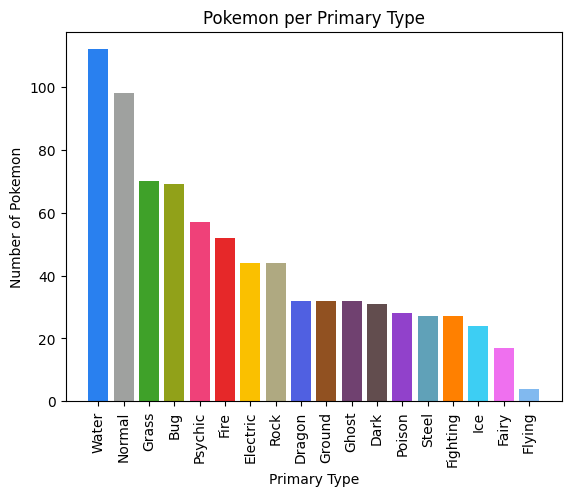

In [32]:
type_counts = db['Type1'].value_counts()
# Pokemon Scarlet/Violet type colors (Bulbapedia).
# https://bulbapedia.bulbagarden.net/wiki/Help:Color_templates#Video_game_types
type_colors = {
    'Normal': '#9FA19F', 'Fire': '#E62829', 'Water': '#2980EF',
    'Electric': '#FAC000', 'Grass': '#3FA129', 'Ice': '#3DCEF3',
    'Fighting': '#FF8000', 'Poison': '#9141CB', 'Ground': '#915121',
    'Flying': '#81B9EF', 'Psychic': '#EF4179', 'Bug': '#91A119',
    'Rock': '#AFA981', 'Ghost': '#704170', 'Dragon': '#5060E1',
    'Dark': '#624D4E', 'Steel': '#60A1B8', 'Fairy': '#EF70EF',
}
plt.bar(type_counts.index, type_counts.values,
        color=[type_colors[pokemon_type] for pokemon_type in type_counts.index])
plt.xticks(rotation=90)
plt.xlabel('Primary Type')
plt.ylabel('Number of Pokemon')
plt.title('Pokemon per Primary Type')
plt.show()

Conclusion: There are 800 Pokemon and 12 features. Water and Normal types are over-represented, and only 65 Pokemon are Legendary.

### Statistical Method 2:

In [33]:
# two-sample t-test: Legendary vs. Non-Legendary Total stats
# Null Hypothesis: Legendary and Non-Legendary Pokemon have the same total stats (mu_legendary = mu_non_legendary)
# Alt Hypothesis: Legendary and Non-Legendary Pokemon have different total stats (mu_legendary != mu_non_legendary)
legendary = db[db['Legendary'] == True]['Total']
non_legendary = db[db['Legendary'] == False]['Total']

t, p = ttest_ind(legendary, non_legendary)
print(f"p-value: {p}")

p-value: 3.0952457469652825e-52


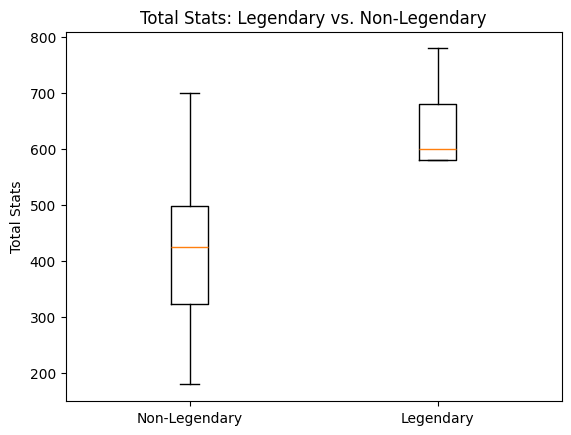

In [34]:
plt.boxplot([non_legendary, legendary], tick_labels=['Non-Legendary', 'Legendary'])
plt.ylabel('Total Stats')
plt.title('Total Stats: Legendary vs. Non-Legendary')
plt.show()

Conclusion: The p-value is below 0.05, so we reject the null hypothesis. Legendary Pokemon have significantly higher total stats.

### Statistical Method 3:

In [35]:
# Pearson correlation: Attack vs. Defense
# Null Hypothesis: Attack and Defense have no linear correlation (r = 0)
# Alt Hypothesis: Attack and Defense have a linear correlation (r != 0)
r, p = pearsonr(db['Attack'], db['Defense'])
print(f"r: {r}")
print(f"p-value: {p}")

r: 0.4386870551184896
p-value: 5.858479864289521e-39


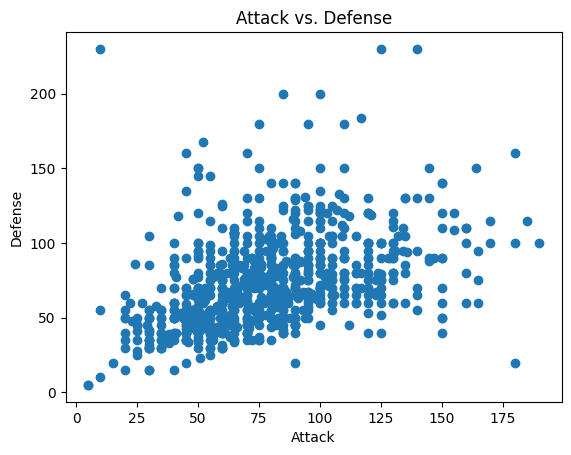

In [36]:
plt.scatter(db['Attack'], db['Defense'])
plt.xlabel('Attack')
plt.ylabel('Defense')
plt.title('Attack vs. Defense')
plt.show()

Conclusion: The p-value is below 0.05, so Attack and Defense are significantly correlated. The correlation is positive but moderate (r ≈ 0.44).